# 3층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 모의고사 다섯 번 — 교차검증

**프롬프트**

> rides.csv 이탈 예측에서 얕은 나무(max_depth=3)와 깊은 나무(제한 없음)를
> 5겹 교차검증으로 비교해 주세요. 점수는 재현율로, 다섯 번 점수와 평균·표준편차를 출력하고
> 막대그래프로 비교해 주세요(그래프 글자는 영어).

shallow (3) 다섯 번: [0.326 0.419 0.727 0.545 0.477] 평균: 0.499 ± 0.135
deep (None) 다섯 번: [0.233 0.14  0.227 0.227 0.091] 평균: 0.184 ± 0.058


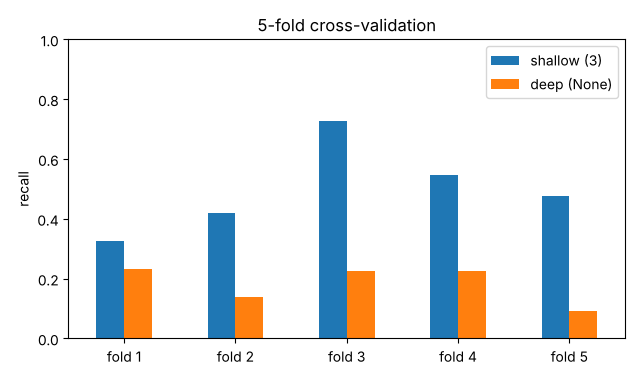

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/rides.csv")
X = df[["distance_km", "duration_min", "hour", "is_weekend", "fare"]]
y = df["churned"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

result = {}
for name, depth in [("shallow (3)", 3), ("deep (None)", None)]:
    tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0)
    s = cross_val_score(tree, X, y, cv=cv, scoring="recall")
    result[name] = s
    print(name, "다섯 번:", s.round(3), "평균:", round(s.mean(), 3), "±", round(s.std(), 3))

pd.DataFrame(result, index=[f"fold {i}" for i in range(1, 6)]).plot.bar(rot=0)
plt.ylabel("recall"); plt.title("5-fold cross-validation"); plt.ylim(0, 1)
plt.show()

**박사의 한 줄 판단** — 얕은 나무 평균 0.499, 깊은 나무 0.184 — 깊은 나무는 외우기만 했습니다. 다만 얕은 나무도 다섯 번 점수가 0.33~0.73으로 크게 흔들려, 한 번 점수만 믿으면 안 됩니다.

## 실습 2 · 새 손님 찾기 — 기준선과 먼저 비교하기

**프롬프트**

> payments.csv에서 새 손님(is_new_user)을 맞히고 싶어요.
> “모두 기존 손님”이라고 답하는 기준선, SVM, k-NN(k=5) 세 가지의
> 정확도와 “시험용 새 손님 중 몇 명을 찾았는지”를 표로 비교해 주세요.
> (금액 amount에 빈 값이 있다고 들었어요. 처리 방법도 알려 주세요.)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/payments.csv")
print("빈 값 개수:", df.isna().sum().to_dict())
df["amount"] = df["amount"].fillna(df["amount"].median())   # 빈 금액은 중앙값으로 채움
X = pd.get_dummies(df[["hour", "items", "amount", "channel", "city"]], dtype=int)
y = df["is_new_user"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {"기준선(모두 기존)": DummyClassifier(strategy="most_frequent"),
          "SVM": make_pipeline(StandardScaler(), SVC()),
          "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5))}
rows = []
for name, m in models.items():
    pred = m.fit(X_train, y_train).predict(X_test)
    found = int(((pred == 1) & (y_test == 1)).sum())
    rows.append([name, round((pred == y_test).mean(), 3), f"{found} / {int(y_test.sum())}"])
print(pd.DataFrame(rows, columns=["모델", "정확도", "찾은 새 손님"]).to_string(index=False))

빈 값 개수: {'date': 0, 'hour': 0, 'city': 0, 'channel': 0, 'items': 0, 'amount': 32, 'is_new_user': 0}
        모델   정확도 찾은 새 손님
기준선(모두 기존) 0.756  0 / 39
       SVM 0.756  0 / 39
k-NN (k=5) 0.681  7 / 39


**박사의 한 줄 판단** — AI 코드가 빈 금액 32개를 중앙값으로 채웠습니다. SVM은 기준선과 똑같이 새 손님을 0명 찾았고, k-NN은 7명을 찾았지만 정확도는 더 낮습니다. 본문 숫자(0.719, 4명)와 다른 것은 나누는 방법과 빈 값 처리가 달라서입니다.